Showcases a hexahedral lattice (lat=2). In a hex lattice, OpenMC indexes universes per ring. 

In [1]:
%run -i clean_script.py
import openmc
import numpy as np

model = openmc.model.Model()

# Material definitions
materials=openmc.Materials()
model.materials = materials

In [2]:
# Surface definitions
s11 = openmc.ZCylinder(r=20, boundary_type='vacuum')
s10 = openmc.Sphere(r=40)
s19 = openmc.ZPlane(31.75, boundary_type='vacuum')
s29 = openmc.ZPlane(-31.75, boundary_type='vacuum')

s301 = openmc.XPlane(1)
s302 = openmc.XPlane(-1)
s303 = openmc.Plane(1,1.7320508076, 0, 2)
s304 = openmc.Plane(-1,1.7320508076, 0, 2)
s305 = openmc.Plane(1,1.7320508076, 0, -2)
s306 = openmc.Plane(-1,1.7320508076, 0, -2)

BoundingBox(lower_left=(-1.0, -inf, -inf), upper_right=(1.0, inf, inf))


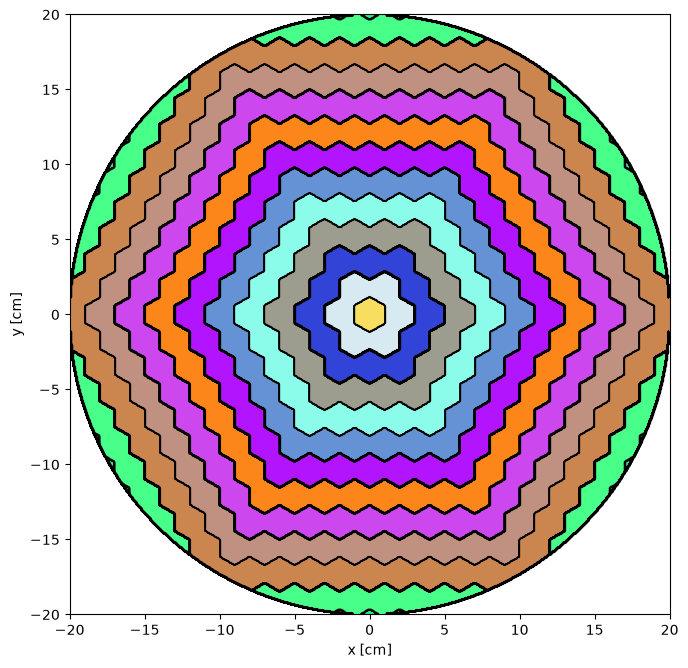

In [3]:
# Cell definitions
def u3():
    c2 = openmc.Cell(fill=None,region=-s10)
    return openmc.Universe(cells=[c2])
    
def u1():
    c3_region = -s301 & +s302 &-s303 & +s305 & -s304 & +s306
    c3 = openmc.Cell(fill=u3(),region=c3_region)
    return openmc.Universe(cells=[c3])

c1 = openmc.Cell(fill=None,region=-s11&-s19&+s29)
c4 = openmc.Cell(fill=None,region=~c1.region)

print(u1().bounding_box)

c1_fill = openmc.HexLattice()
c1_fill.center = (0,0)
c1_fill.pitch=[2]
c1_fill.orientation='x'


no_rings = 21 
num_uni = [i for i in range(0,6*no_rings,6)]
num_uni[0] = 1
num_uni = num_uni[::-1] # goes from outer to inner

c1_fill.universes=[[u1()]*x for x in num_uni]
c1_fill.outer=openmc.Universe(cells=[c4])
    
c1.fill=c1_fill
geom = openmc.Geometry([c1,c4])
geom.plot(width=(40,40),outline=True,pixels=(600,600))
model.geometry = geom

In [4]:
settings = openmc.Settings()
settings.run_mode='fixed source'
settings.particles = 200
settings.batches = 10

source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,0,0))
source.energy = openmc.stats.delta_function(14e6)

settings.source = source

model.settings = settings

In [5]:
tallies = openmc.Tallies()
f1 = openmc.Tally()
f1.name = "f1"
f1.filters = [openmc.SurfaceFilter(s11)]
f1.scores = ["current"]

tallies.append(f1)
model.tallies = tallies

In [6]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [7]:
with openmc.StatePoint(sp_filename) as sp:
    tally = sp.get_tally()
    df = tally.get_pandas_dataframe()
    print(df)

   surface nuclide    score     mean  std. dev.
0        1   total  current 8.47e-01   6.19e-03


In [8]:
w = 45
plots = openmc.Plots()

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
plots.append(plot)

model.plots=plots
#model.export_to_xml()

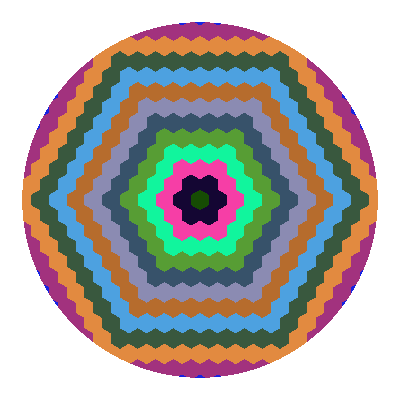

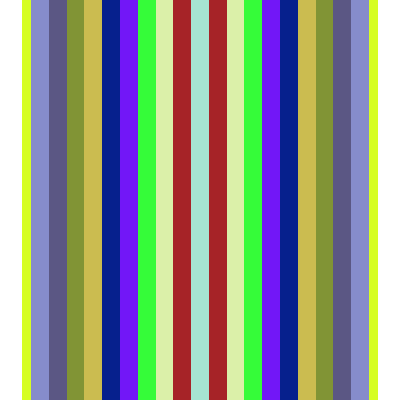

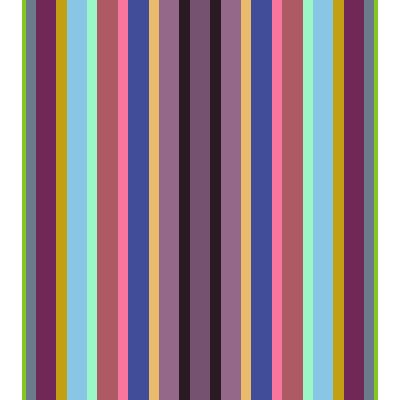

In [9]:
openmc.plot_inline(plots)